# Kidney on Dixon (case)

This example shows the use of the {py:func}`~miblab_dl.kidney_dixon` model to 
segment kidney parenchyma on Dixon data.

In [1]:
import numpy as np
import miblab_dl as dl
from miblab_plot import mosaic_overlay

from _data_loader import dixon_case

## Download data

In [2]:
array_4d, spacing = dixon_case()

## Predict kidney masks

In [3]:
kidneys = dl.kidney_dixon(array_4d, verbose=False)

perform_everything_on_device=True is only supported for cuda devices! Setting this to False


## Compute rsf candidates

In [4]:
water, fat = array_4d[..., 2], array_4d[..., 3]
rsf_candidates = dl.rsf_candidates(fat, water, kidneys, fat_threshold=0.5)

## Combine all labels

In [5]:
# Increment rsf labels so they are different from kidney labels
rsf_candidates[rsf_candidates > 0] += 2

# Combine into one label (rsf takes precedence on overlap)
label_image = np.where(rsf_candidates > 0, rsf_candidates, kidneys)

## Display resulting label

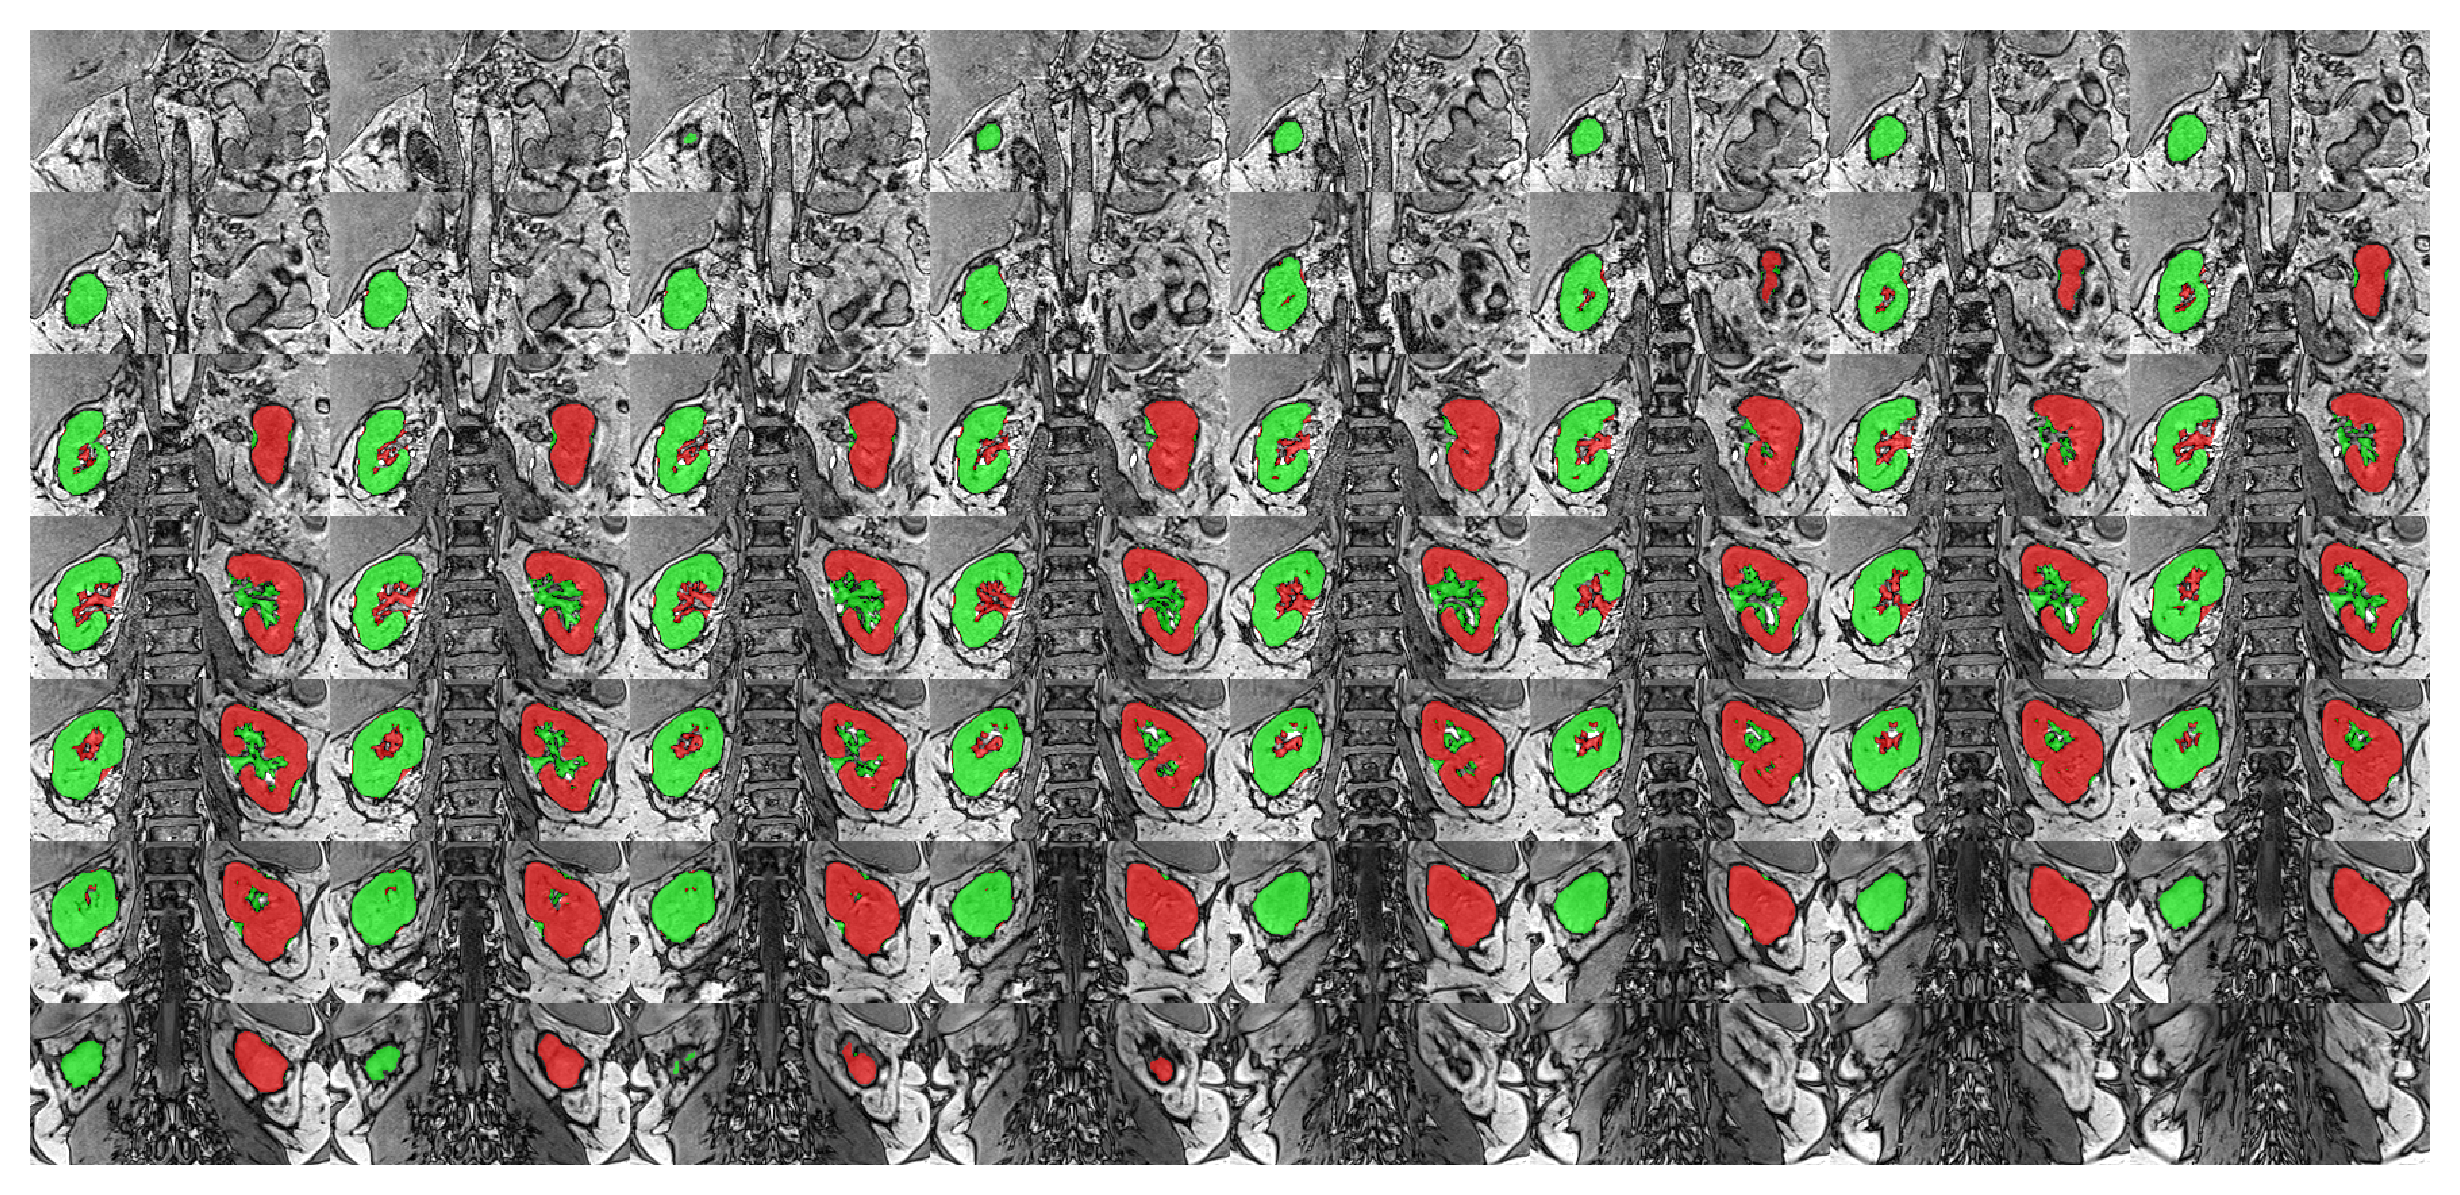

In [6]:
%matplotlib inline

out_phase = array_4d[...,0]
colors = [
    [1.0, 0.0, 0.0, 0.6],   # red
    [0.0, 1.0, 0.0, 0.6],   # green
    [0.0, 1.0, 0.0, 0.6],   # green
    [1.0, 0.0, 0.0, 0.6],   # red
]
mosaic_overlay(
    out_phase,
    label_image,
    margin=[16,16,2],
    verbose=0,
    colors=colors,
)

## Repeat with a lower fat threshold

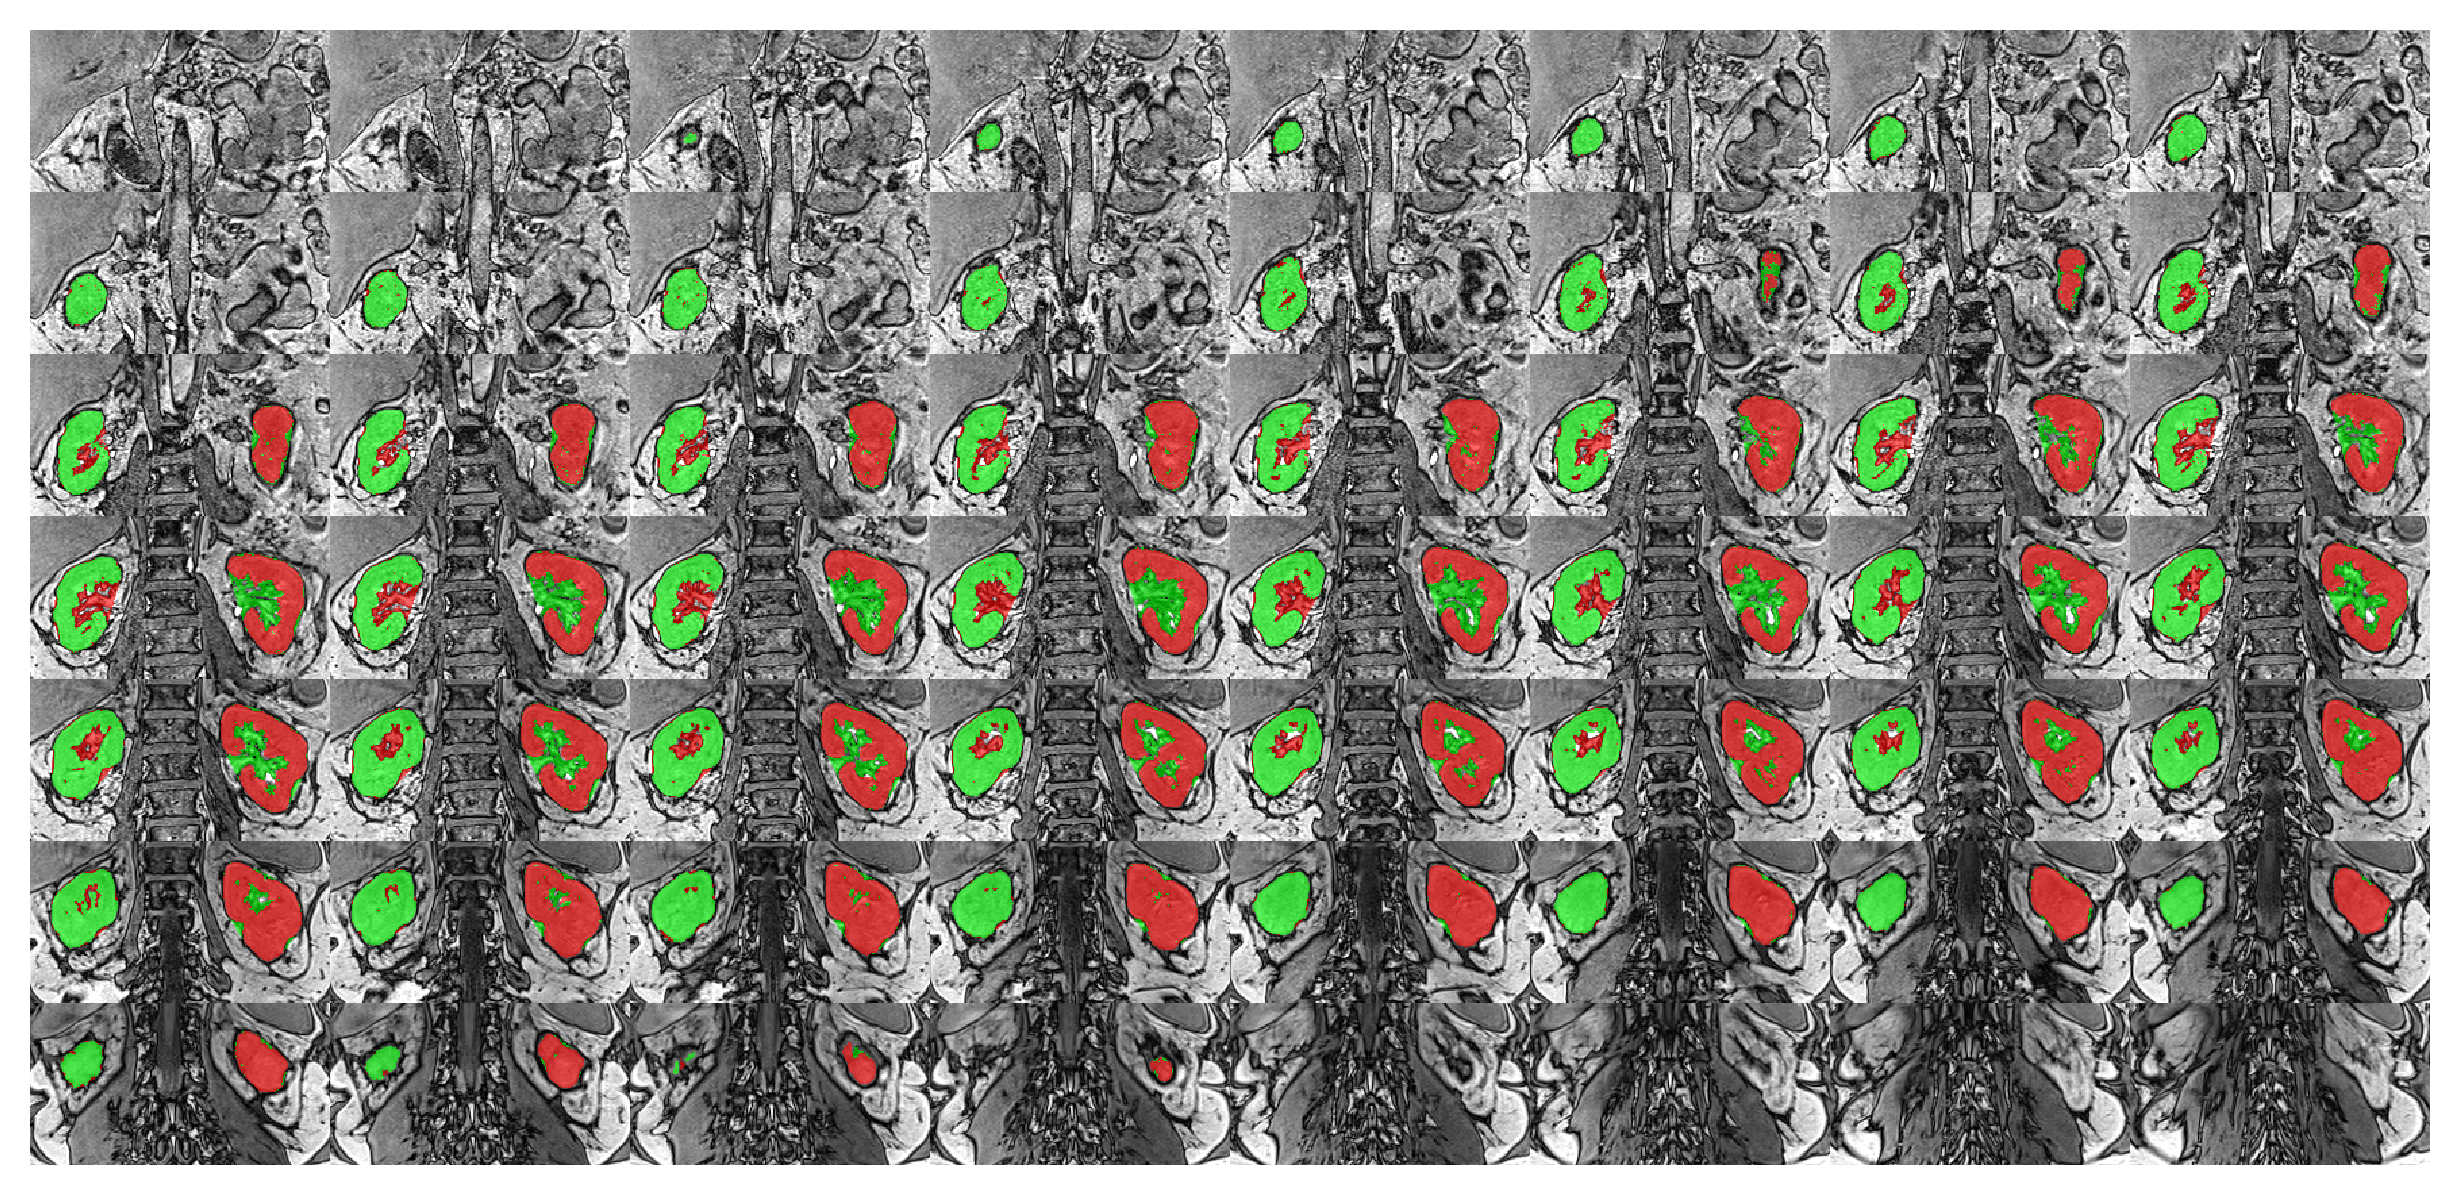

In [7]:
%matplotlib inline
rsf_candidates = dl.rsf_candidates(fat, water, kidneys, fat_threshold=0.25)
rsf_candidates[rsf_candidates > 0] += 2
label_image = np.where(rsf_candidates > 0, rsf_candidates, kidneys)
mosaic_overlay(
    out_phase,
    label_image,
    margin=[16,16,2],
    verbose=0,
    colors=colors,
)